In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from keras import Sequential

In [ ]:
df = pd.read_csv("/content/Churn_Modelling.csv")

In [ ]:
df.head()
df.shape

(10000, 12)

In [ ]:
df.drop(columns=["RowNumber","CustomerId","Surname"],inplace=True)

In [ ]:
df.isnull().sum()

,0
CreditScore,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0
HasCrCard,0
IsActiveMember,0
EstimatedSalary,0
Exited,0
Geography_Germany,0


In [ ]:
df = pd.get_dummies(df,columns=["Geography","Gender"],drop_first=True )

KeyError: "None of [Index(['Geography', 'Gender'], dtype='object')] are in the [columns]"

In [ ]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [ ]:
X = df.drop(columns=["Exited"],axis=1)
y = df["Exited"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test =  train_test_split(X,y,random_state=42,test_size=0.2)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



In [ ]:
from tensorflow.keras.layers import Dense
model = Sequential()
model.add(Dense(16, input_dim=X_train.shape[1], activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer="adam", loss="binary_crossentropy",metrics=["accuracy"])

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 11)
y_train shape: (8000,)
X_test shape: (2000, 11)
y_test shape: (2000,)


In [ ]:
model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7897 - loss: 0.5055 - val_accuracy: 0.8125 - val_loss: 0.4399
Epoch 2/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8085 - loss: 0.4399 - val_accuracy: 0.8300 - val_loss: 0.4119
Epoch 3/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8211 - loss: 0.4204 - val_accuracy: 0.8338 - val_loss: 0.3990
Epoch 4/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8290 - loss: 0.4080 - val_accuracy: 0.8413 - val_loss: 0.3920
Epoch 5/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8360 - loss: 0.3956 - val_accuracy: 0.8425 - val_loss: 0.3790
Epoch 6/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8443 - loss: 0.3824 - val_accuracy: 0.8462 - val_loss: 0.3683
Epoch 7/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8510 - loss: 0.3700 - val_accuracy: 0.8475 - val_loss: 0.3591
Epoch 8/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8540 - loss: 0.3615 - val_accuracy: 0.

In [ ]:
y_pred_prob = model.predict(X_test)
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score,recall_score,f1_score

y_pred= (y_pred_prob > 0.5).astype(int)

print(accuracy_score(y_test,y_test))
print(confusion_matrix(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))
cm = confusion_matrix(y_test,y_pred)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1.0
[[1554   53]
 [ 227  166]]
0.7579908675799086
0.4223918575063613
0.5424836601307189


Text(95.72222222222221, 0.5, 'Actual')

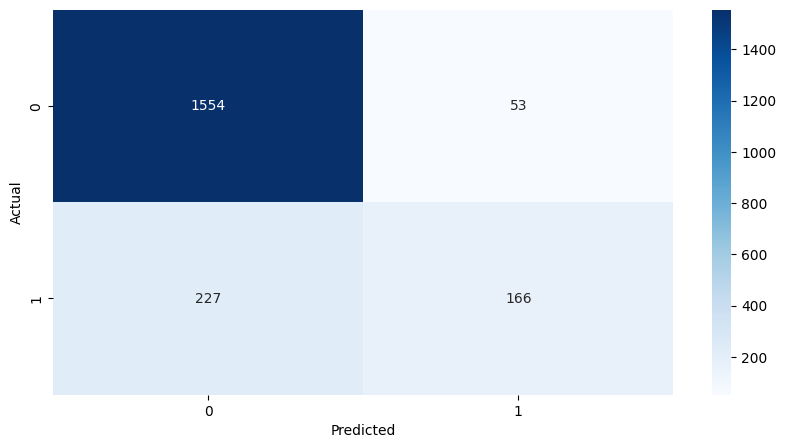

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
